# Lab 3 — Apprendre : rétropropagation et optimiseurs

**ENSIM · 5A ASTRE · De l'IA au LLM agentique · Séance 3**

Ce lab se fait **en autonomie, après la séance**. Il valide la séance 3 : chaque exemple numérique des diapositives est recalculé ici, puis appliqué aux deux cas du fil rouge « maintenance prédictive ».

## Objectifs

À la fin du lab, vous savez :

1. calculer un gradient **à la main** par la règle de la chaîne, et le vérifier avec l'**autograd** de PyTorch ;
2. expliquer l'effet de l'**initialisation** et de la profondeur sur les gradients ;
3. comparer **SGD, momentum, RMSProp et Adam** sur un même problème ;
4. entraîner et évaluer un **MLP de classification** (pannes AI4I : précision, rappel, F1) et un **MLP de régression** (durée de vie restante C-MAPSS : RMSE) ;
5. exporter un modèle en **ONNX**, le **quantifier en int8** et mesurer ce que l'on gagne et perd pour un STM32.

## Prérequis

- Séances 2 et 3 : neurone, MLP, sigmoïde, BCE, descente de gradient.
- Python, NumPy, notions de PyTorch (`torch.tensor`, `nn.Linear`).
- **Environnement** : Google Colab gratuit. **Un CPU suffit**, il n'est pas utile d'activer un GPU. Durée d'exécution complète : environ 2 minutes.

## Plan

| Partie | Contenu |
|---|---|
| 1 | Rappel des formules clés |
| 2 | La règle de la chaîne sur un neurone |
| 3 | Le fil rouge 2-2-1 : à la main en NumPy, puis par l'autograd |
| 4 | Profondeur : gradients qui disparaissent, initialisation |
| 5 | Optimiseurs : un pas de chaque, puis courbes de perte |
| 6 | Régularisation et métriques sur de petits exemples |
| 7 | Cas 1 : classer les pannes (AI4I 2020) |
| 8 | Cas 2 : estimer la durée de vie restante (NASA C-MAPSS FD001) |
| 9 | Vers la cible : mémoire, ONNX, quantification int8 |
| 10 | Exercices de validation |
| 11 | Corrigé |

## Données

| Jeu | Source | Licence |
|---|---|---|
| AI4I 2020 Predictive Maintenance (Matzka, 2020) | UCI Machine Learning Repository, id 601 ; repli `ucimlrepo` | CC BY 4.0 |
| NASA C-MAPSS, *Turbofan Engine Degradation Simulation* (Saxena et Goebel, 2008), sous-ensemble FD001 | NASA Prognostics Data Repository (archive `phm-datasets`) ; repli : miroir GitHub `hankroark/Turbofan-Engine-Degradation`, fichiers identiques | Données publiques de la NASA |

## 1. Rappel des formules clés

**Neurone et MLP.** $z = W\mathbf{x} + \mathbf{b}$, $\;\mathbf{h} = \sigma(z)$, $\;\sigma(z) = \dfrac{1}{1+e^{-z}}$, $\;\sigma'(z) = \sigma(z)\,(1-\sigma(z)) \le 0{,}25$.

**Pertes.** $\mathcal{L}_{\text{MSE}} = \tfrac12(\hat y - y)^2$ ; $\;\mathcal{L}_{\text{BCE}} = -\big[y\ln\hat y + (1-y)\ln(1-\hat y)\big]$.

**Règle de la chaîne (un neurone, MSE).** $\dfrac{\partial \mathcal{L}}{\partial w} = \dfrac{\partial \mathcal{L}}{\partial \hat y}\cdot\dfrac{\partial \hat y}{\partial z}\cdot\dfrac{\partial z}{\partial w} = (\hat y - y)\,\sigma'(z)\,x$.

**Rétropropagation (couche $l$).**
- sortie sigmoïde avec BCE : $\delta^{(L)} = \hat y - y$ ;
- couche cachée : $\delta^{(l)} = \big(W^{(l+1)\top}\delta^{(l+1)}\big)\odot\sigma'(z^{(l)})$ ;
- gradients : $\dfrac{\partial \mathcal{L}}{\partial W^{(l)}} = \delta^{(l)}\,\mathbf{a}^{(l-1)\top}$, $\;\dfrac{\partial \mathcal{L}}{\partial \mathbf{b}^{(l)}} = \delta^{(l)}$ ;
- mise à jour : $\theta \leftarrow \theta - \eta\,\nabla_\theta\mathcal{L}$.

**Initialisation.** Xavier (Glorot et Bengio, 2010) : $\mathrm{Var}(W) = \dfrac{2}{n_\text{in}+n_\text{out}}$. He (He et al., 2015) : $\mathrm{Var}(W) = \dfrac{2}{n_\text{in}}$.

**Optimiseurs.**
- momentum : $v \leftarrow \beta v + g$, $\;\theta \leftarrow \theta - \eta v$ (convention de PyTorch) ;
- Adam (Kingma et Ba, 2014) : $m \leftarrow \beta_1 m + (1-\beta_1) g$, $\;v \leftarrow \beta_2 v + (1-\beta_2) g^2$, $\;\hat m = \dfrac{m}{1-\beta_1^t}$, $\;\hat v = \dfrac{v}{1-\beta_2^t}$, $\;\theta \leftarrow \theta - \eta\,\dfrac{\hat m}{\sqrt{\hat v}+\varepsilon}$.

**Régularisation.** L2 : $\mathcal{L} + \tfrac{\lambda}{2}\lVert \mathbf{w}\rVert^2$, de gradient $\lambda\mathbf{w}$. Dropout inversé : $\tilde h = \dfrac{m \odot h}{1-p}$ pendant l'entraînement.

**Métriques.** Précision $= \dfrac{TP}{TP+FP}$, rappel $= \dfrac{TP}{TP+FN}$, $F_1 = \dfrac{2PR}{P+R}$ ; $\;\text{MAE} = \dfrac1n\sum|\hat y_i - y_i|$, $\;\text{RMSE} = \sqrt{\dfrac1n\sum(\hat y_i - y_i)^2}$.

**Quantification affine int8.** $q = \mathrm{round}(x/s) + z$, avec $s = \dfrac{x_\max - x_\min}{255}$ et $z = -128 - \mathrm{round}(x_\min/s)$ ; retour : $\hat x = s\,(q - z)$.

### Installation et imports

Sur Colab, `torch`, `scikit-learn` et `pandas` sont déjà installés. Les paquets ONNX sont installés seulement s'ils manquent.

In [1]:
try:
    import onnx, onnxruntime, onnxscript
except ImportError:
    %pip install -q onnx onnxruntime onnxscript
    import onnx, onnxruntime, onnxscript

import copy, io, math, os, shutil, tempfile, time, warnings, logging, zipfile, contextlib, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.ERROR)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
SEED = 42
torch.manual_seed(SEED)
DOSSIER = tempfile.mkdtemp(prefix="lab3_")   # fichiers temporaires (ONNX, modèles), supprimés à la fin
T0 = time.time()
print("torch", torch.__version__, "| onnx", onnx.__version__, "| onnxruntime", onnxruntime.__version__)

def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))

torch 2.15.0 | onnx 1.23.2 | onnxruntime 1.24.3


## 2. La règle de la chaîne sur un neurone

Exemple des diapositives : $x = 2$, $w = 0{,}5$, $b = -0{,}5$, cible $y = 1$, perte $\mathcal{L} = \tfrac12(\hat y - y)^2$.

On calcule $\dfrac{\partial \mathcal{L}}{\partial w} = (\hat y - y)\,\sigma'(z)\,x$, puis on le vérifie par **différences finies** : $\dfrac{\mathcal{L}(w+\varepsilon) - \mathcal{L}(w-\varepsilon)}{2\varepsilon}$. C'est le *gradient check*, le test standard d'une rétropropagation écrite à la main.

In [2]:
x, w, b, y = 2.0, 0.5, -0.5, 1.0
z = w * x + b
y_hat = sigmoide(z)
L = 0.5 * (y_hat - y) ** 2
d_sigma = y_hat * (1 - y_hat)

dL_dyhat = y_hat - y
dL_dz = dL_dyhat * d_sigma
dL_dw = dL_dz * x
dL_db = dL_dz

print(f"z = {z:.3g}   y_hat = {y_hat:.3g}   L = {L:.3g}")
print(f"dL/dy_hat = {dL_dyhat:.3g}   sigma'(z) = {d_sigma:.3g}   dL/dz = {dL_dz:.3g}")
print(f"dL/dw = {dL_dw:.3g}   dL/db = {dL_db:.3g}")

eps = 1e-3
perte = lambda w_: 0.5 * (sigmoide(w_ * x + b) - y) ** 2
print(f"Différences finies : {(perte(w + eps) - perte(w - eps)) / (2 * eps):.3g}  (attendu : {dL_dw:.3g})")

z = 0.5   y_hat = 0.622   L = 0.0713
dL/dy_hat = -0.378   sigma'(z) = 0.235   dL/dz = -0.0887
dL/dw = -0.177   dL/db = -0.0887
Différences finies : -0.177  (attendu : -0.177)


## 3. Le fil rouge : un réseau 2-2-1 entièrement sigmoïde

C'est le réseau de la séance, avec les poids des diapositives :

$$W_1 = \begin{pmatrix} 0{,}5 & -0{,}5 \\ 0{,}3 & 0{,}8 \end{pmatrix},\quad \mathbf{b}_1 = \begin{pmatrix}0\\0\end{pmatrix},\quad \mathbf{w}_2 = (1,\ -1),\quad b_2 = 0.$$

Entrée $\mathbf{x} = (1, 0)$ de XOR, cible $y = 1$, perte **BCE**. Avec une sortie sigmoïde, la BCE donne $\delta_2 = \hat y - y$ : le terme $\sigma'(z_2)$ disparaît, et le gradient reste fort même quand la sortie sature.

### 3.1 À la main, en NumPy

In [3]:
W1 = np.array([[0.5, -0.5],
               [0.3,  0.8]])
b1 = np.array([0.0, 0.0])
W2 = np.array([1.0, -1.0])
b2 = 0.0
xv = np.array([1.0, 0.0])
y = 1.0
eta = 0.5

def bce(y_hat, y):
    return -(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

def forward(W1, b1, W2, b2, xv):
    z1 = W1 @ xv + b1
    h = sigmoide(z1)
    z2 = W2 @ h + b2
    y_hat = sigmoide(z2)
    return z1, h, z2, y_hat

# --- forward
z1, h, z2, y_hat = forward(W1, b1, W2, b2, xv)
L0 = bce(y_hat, y)
print("FORWARD")
print(f"  z1 = W1 x + b1 = {z1}")
print(f"  h  = sigma(z1) = {h}")
print(f"  z2 = w2 . h + b2 = {z2:.4f}")
print(f"  y_hat = sigma(z2) = {y_hat:.4f}")
print(f"  L (BCE) = {L0:.4f}")

# --- backward
delta2 = y_hat - y                       # sortie sigmoïde + BCE
gW2 = delta2 * h
gb2 = delta2
delta1 = (W2 * delta2) * h * (1 - h)     # (W2^T delta2) ⊙ sigma'(z1)
gW1 = np.outer(delta1, xv)
gb1 = delta1
print("BACKWARD")
print(f"  delta2 = y_hat - y = {delta2:.4f}")
print(f"  dL/dw2 = delta2 * h = {gW2}    dL/db2 = {gb2:.4f}")
print(f"  sigma'(z1) = {h * (1 - h)}")
print(f"  delta1 = {delta1}")
print(f"  dL/dW1 =\n{gW1}")
print(f"  dL/db1 = {gb1}")

# --- mise à jour
W1n, b1n = W1 - eta * gW1, b1 - eta * gb1
W2n, b2n = W2 - eta * gW2, b2 - eta * gb2
_, hn, z2n, y_hat_n = forward(W1n, b1n, W2n, b2n, xv)
L1 = bce(y_hat_n, y)
print("MISE À JOUR (eta = 0,5)")
print(f"  W1 =\n{W1n}\n  b1 = {b1n}\n  w2 = {W2n}   b2 = {b2n:.4f}")
print(f"  y_hat : {y_hat:.3f} -> {y_hat_n:.3f}     perte : {L0:.3f} -> {L1:.3f}  ({(L1 - L0) / L0:+.0%})")

FORWARD
  z1 = W1 x + b1 = [0.5 0.3]
  h  = sigma(z1) = [0.6225 0.5744]
  z2 = w2 . h + b2 = 0.0480
  y_hat = sigma(z2) = 0.5120
  L (BCE) = 0.6694
BACKWARD
  delta2 = y_hat - y = -0.4880
  dL/dw2 = delta2 * h = [-0.3038 -0.2803]    dL/db2 = -0.4880
  sigma'(z1) = [0.235  0.2445]
  delta1 = [-0.1147  0.1193]
  dL/dW1 =
[[-0.1147 -0.    ]
 [ 0.1193  0.    ]]
  dL/db1 = [-0.1147  0.1193]
MISE À JOUR (eta = 0,5)
  W1 =
[[ 0.5573 -0.5   ]
 [ 0.2404  0.8   ]]
  b1 = [ 0.0573 -0.0596]
  w2 = [ 1.1519 -0.8598]   b2 = 0.2440
  y_hat : 0.512 -> 0.628     perte : 0.669 -> 0.465  (-30%)


**À observer.**

- Les gradients de la 2ᵉ colonne de $W_1$ sont **nuls** : l'entrée $x_2 = 0$ ne transmet aucun gradient à ses poids.
- Une seule mise à jour fait passer $\hat y$ de 0,512 à 0,628 et la perte de 0,669 à 0,465.

### 3.2 Le même calcul par l'autograd de PyTorch

On décrit seulement le **forward**. `loss.backward()` parcourt le graphe de calcul à l'envers et remplit `.grad` pour chaque tenseur créé avec `requires_grad=True`. On travaille en `float64` pour comparer exactement avec NumPy.

In [4]:
tW1 = torch.tensor(W1, requires_grad=True)
tb1 = torch.tensor(b1, requires_grad=True)
tW2 = torch.tensor(W2, requires_grad=True)
tb2 = torch.tensor(b2, dtype=torch.float64, requires_grad=True)
tx = torch.tensor(xv)
ty = torch.tensor(y, dtype=torch.float64)

y_hat_t = torch.sigmoid(tW2 @ torch.sigmoid(tW1 @ tx + tb1) + tb2)
loss = nn.functional.binary_cross_entropy(y_hat_t, ty)
loss.backward()

print(f"perte : {loss.item():.4f}")
for nom, t, ref in [("dL/dW1", tW1, gW1), ("dL/db1", tb1, gb1), ("dL/dw2", tW2, gW2), ("dL/db2", tb2, gb2)]:
    print(f"{nom} autograd = {t.grad.numpy().round(4)}   identique au calcul à la main : {np.allclose(t.grad.numpy(), ref)}")

# Un pas de descente de gradient avec l'optimiseur de PyTorch
opt = torch.optim.SGD([tW1, tb1, tW2, tb2], lr=0.5)
opt.step()
with torch.no_grad():
    y_hat_t2 = torch.sigmoid(tW2 @ torch.sigmoid(tW1 @ tx + tb1) + tb2)
    print(f"après torch.optim.SGD : y_hat = {y_hat_t2.item():.3f}, perte = {nn.functional.binary_cross_entropy(y_hat_t2, ty).item():.3f}")

perte : 0.6694
dL/dW1 autograd = [[-0.1147 -0.    ]
 [ 0.1193  0.    ]]   identique au calcul à la main : True
dL/db1 autograd = [-0.1147  0.1193]   identique au calcul à la main : True
dL/dw2 autograd = [-0.3038 -0.2803]   identique au calcul à la main : True
dL/db2 autograd = -0.488   identique au calcul à la main : True


après torch.optim.SGD : y_hat = 0.628, perte = 0.465


### 3.3 Et avec la MSE ?

Avec $\mathcal{L} = \tfrac12(\hat y - y)^2$, on aurait $\delta_2 = (\hat y - y)\,\sigma'(z_2)$. Comparons les deux pertes quand la sortie est juste ou très fausse.

In [5]:
for yh in [y_hat, 0.01]:
    d_bce = yh - 1
    d_mse = (yh - 1) * yh * (1 - yh)
    print(f"y_hat = {yh:.3f} :  delta2 BCE = {d_bce:+.3f}   delta2 MSE = {d_mse:+.4f}")
print("Quand le réseau se trompe franchement (y_hat = 0,01), la MSE ne donne presque plus de gradient : l'apprentissage cale.")

y_hat = 0.512 :  delta2 BCE = -0.488   delta2 MSE = -0.1219
y_hat = 0.010 :  delta2 BCE = -0.990   delta2 MSE = -0.0098
Quand le réseau se trompe franchement (y_hat = 0,01), la MSE ne donne presque plus de gradient : l'apprentissage cale.


## 4. Profondeur : gradients qui disparaissent, initialisation

### 4.1 Le produit des dérivées

En remontant $n$ couches, le gradient est multiplié par $n$ facteurs $w_k\,\sigma'(z_k)$. Avec la sigmoïde, $\sigma' \le 0{,}25$.

In [6]:
print(f"Sigmoïde, 10 couches, w = 1 : 0,25^10 = {0.25 ** 10:.3g}")
print(f"ReLU (z > 0), 10 couches, w = 1 : 1^10 = {1.0 ** 10:.3g}")
print(f"ReLU, 10 couches, w = 2 : 2^10 = {2.0 ** 10:.0f}  -> explosion")

Sigmoïde, 10 couches, w = 1 : 0,25^10 = 9.54e-07
ReLU (z > 0), 10 couches, w = 1 : 1^10 = 1
ReLU, 10 couches, w = 2 : 2^10 = 1024  -> explosion


### 4.2 Mesure sur un réseau de 10 couches

On construit deux MLP de 10 couches cachées de 32 neurones :

- un MLP sigmoïde, initialisé par Xavier ;
- un MLP ReLU, initialisé par He.

On mesure la norme du gradient des poids de chaque couche, pour un même lot de données.

sigmoïde + Xavier  : couche 1 / couche 10 = 8.25e-07
ReLU + He          : couche 1 / couche 10 = 3.35e-01


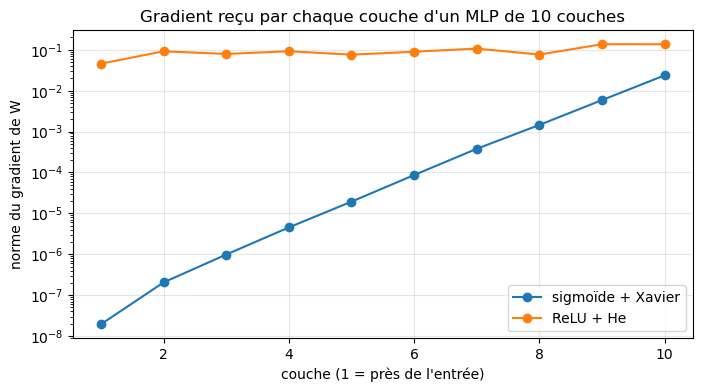

In [7]:
def mlp_profond(activation, init, profondeur=10, largeur=32):
    couches, d = [], 8
    for _ in range(profondeur):
        lin = nn.Linear(d, largeur)
        init(lin.weight); nn.init.zeros_(lin.bias)
        couches += [lin, activation()]
        d = largeur
    couches.append(nn.Linear(d, 1))
    return nn.Sequential(*couches)

torch.manual_seed(SEED)
Xp = torch.randn(256, 8)
yp = (Xp[:, 0] * Xp[:, 1] > 0).float()
normes = {}
for nom, act, init in [("sigmoïde + Xavier", nn.Sigmoid, nn.init.xavier_normal_),
                       ("ReLU + He", nn.ReLU, lambda t: nn.init.kaiming_normal_(t, nonlinearity="relu"))]:
    torch.manual_seed(SEED)
    m = mlp_profond(act, init)
    perte = nn.functional.binary_cross_entropy_with_logits(m(Xp).squeeze(1), yp)
    perte.backward()
    normes[nom] = [c.weight.grad.norm().item() for c in m if isinstance(c, nn.Linear)][:-1]

couche = np.arange(1, 11)
for nom, n in normes.items():
    plt.semilogy(couche, n, "o-", label=nom)
    print(f"{nom:18s} : couche 1 / couche 10 = {n[0] / n[-1]:.2e}")
plt.xlabel("couche (1 = près de l'entrée)"); plt.ylabel("norme du gradient de W")
plt.title("Gradient reçu par chaque couche d'un MLP de 10 couches"); plt.legend(); plt.show()

### 4.3 Xavier et He pour une couche 256 → 128

On calcule les variances théoriques, puis on les compare à celles des fonctions de `torch.nn.init`.

In [8]:
n_in, n_out = 256, 128
var_xavier, var_he = 2 / (n_in + n_out), 2 / n_in
print(f"Xavier : Var = 2/(256+128) = {var_xavier:.3g}   écart-type = {math.sqrt(var_xavier):.3g}   borne uniforme = {math.sqrt(6 / (n_in + n_out)):.3g}")
print(f"He     : Var = 2/256       = {var_he:.3g}   écart-type = {math.sqrt(var_he):.3g}")

torch.manual_seed(SEED)
Wx = torch.empty(n_out, n_in); nn.init.xavier_normal_(Wx)
Wh = torch.empty(n_out, n_in); nn.init.kaiming_normal_(Wh, nonlinearity="relu")
print(f"Mesuré : Var Xavier = {Wx.var().item():.3g}   Var He = {Wh.var().item():.3g}")

# Pourquoi c'est important : écart-type des activations le long de 10 couches ReLU de 256 neurones
torch.manual_seed(SEED)
a0 = torch.randn(1000, 256)
for nom, sd in [("N(0 ; 0,01²)", 0.01), ("N(0 ; 1)", 1.0), ("He", math.sqrt(2 / 256))]:
    a, ecarts = a0, []
    for _ in range(10):
        a = torch.relu(a @ (torch.randn(256, 256) * sd))
        ecarts.append(a.std().item())
    print(f"{nom:13s} : écart-type des activations, couches 1, 5, 10 = {ecarts[0]:.3g}, {ecarts[4]:.3g}, {ecarts[9]:.3g}")

Xavier : Var = 2/(256+128) = 0.00521   écart-type = 0.0722   borne uniforme = 0.125
He     : Var = 2/256       = 0.00781   écart-type = 0.0884
Mesuré : Var Xavier = 0.00525   Var He = 0.00793
N(0 ; 0,01²)  : écart-type des activations, couches 1, 5, 10 = 0.0937, 1.35e-05, 2.23e-10
N(0 ; 1)      : écart-type des activations, couches 1, 5, 10 = 9.33, 1.62e+05, 2.97e+10
He            : écart-type des activations, couches 1, 5, 10 = 0.832, 0.765, 0.663


## 5. Optimiseurs

### 5.1 Un pas de chaque optimiseur

Exemple des diapositives : $\theta_0 = (1 ;\ 1)$, gradient $g = (0{,}5 ;\ 0{,}01)$, $\eta = 0{,}1$. On calcule à la main, puis on vérifie avec `torch.optim`.

In [9]:
theta0 = np.array([1.0, 1.0]); g = np.array([0.5, 0.01]); lr = 0.1

# SGD
sgd = theta0 - lr * g
# Momentum (beta = 0,9), deux pas avec le même gradient
v1 = g; th1 = theta0 - lr * v1
v2 = 0.9 * v1 + g; th2 = th1 - lr * v2
# Adam, pas 1
b1_, b2_, eps = 0.9, 0.999, 1e-8
m1 = (1 - b1_) * g; s1 = (1 - b2_) * g ** 2
m_hat, s_hat = m1 / (1 - b1_), s1 / (1 - b2_)
adam = theta0 - lr * m_hat / (np.sqrt(s_hat) + eps)
sans_corr = lr * m1 / (np.sqrt(s1) + eps)

print(f"SGD                 : theta1 = {sgd}")
print(f"Momentum, pas 1     : theta1 = {th1}   pas 2 : v2 = {v2}, theta2 = {th2}")
print(f"Adam, pas 1         : m = {m1}, v = {s1}, m_hat = {m_hat}, v_hat = {s_hat}")
print(f"                      theta1 = {adam.round(4)}  (pas de 0,1 pour les DEUX composantes)")
print(f"Adam sans correction de biais : pas = {sans_corr.round(3)}, soit {sans_corr[0] / lr:.2f} fois trop grand")

def pas_torch(fabrique, n_pas=1):
    p = torch.tensor(theta0, requires_grad=True)
    opt = fabrique([p])
    for _ in range(n_pas):
        p.grad = torch.tensor(g); opt.step()
    return p.detach().numpy()

print("Vérification torch.optim :")
print("  SGD      ", pas_torch(lambda p: torch.optim.SGD(p, lr=lr)))
print("  Momentum ", pas_torch(lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9), n_pas=2))
print("  Adam     ", pas_torch(lambda p: torch.optim.Adam(p, lr=lr, betas=(0.9, 0.999))).round(4))

SGD                 : theta1 = [0.95  0.999]
Momentum, pas 1     : theta1 = [0.95  0.999]   pas 2 : v2 = [0.95  0.019], theta2 = [0.855  0.9971]
Adam, pas 1         : m = [0.05  0.001], v = [0.0003 0.    ], m_hat = [0.5  0.01], v_hat = [0.25   0.0001]
                      theta1 = [0.9 0.9]  (pas de 0,1 pour les DEUX composantes)
Adam sans correction de biais : pas = [0.316 0.316], soit 3.16 fois trop grand
Vérification torch.optim :
  SGD       [0.95  0.999]
  Momentum  [0.855  0.9971]
  Adam      [0.9 0.9]


### 5.2 Le taux d'apprentissage sur $f(\theta) = \theta^2$

Le gradient vaut $2\theta$, donc $\theta \leftarrow (1 - 2\eta)\,\theta$. Selon $\eta$, on converge lentement, en un pas, en oscillant, ou on diverge.

In [10]:
for eta_ in [0.1, 0.5, 0.9, 1.1]:
    th, suite = 1.0, [1.0]
    for _ in range(5):
        th -= eta_ * 2 * th
        suite.append(th)
    print(f"eta = {eta_:<4} facteur (1 - 2 eta) = {1 - 2 * eta_:+.1f} : {np.round(suite, 3)}")

eta = 0.1  facteur (1 - 2 eta) = +0.8 : [1.    0.8   0.64  0.512 0.41  0.328]
eta = 0.5  facteur (1 - 2 eta) = +0.0 : [1. 0. 0. 0. 0. 0.]
eta = 0.9  facteur (1 - 2 eta) = -0.8 : [ 1.    -0.8    0.64  -0.512  0.41  -0.328]
eta = 1.1  facteur (1 - 2 eta) = -1.2 : [ 1.    -1.2    1.44  -1.728  2.074 -2.488]


### 5.3 Quatre optimiseurs sur le même problème : XOR

On entraîne le réseau 2-2-1 du fil rouge sur les **4 points de XOR**, depuis les **mêmes poids initiaux** (ceux des diapositives), en lot complet (*full batch*).

Chaque optimiseur garde un taux d'apprentissage usuel pour lui :

| Optimiseur | Taux d'apprentissage $\eta$ |
|---|---|
| SGD | 0,5 |
| Momentum | 0,5, avec $\beta = 0{,}9$ |
| RMSProp | 0,01 |
| Adam | 0,05 |

SGD (eta = 0,5)                    perte < 0,1 après 1318 itérations ; sorties finales = [0.01  0.986 0.991 0.009]


Momentum (eta = 0,5 ; beta = 0,9)  perte < 0,1 après 186 itérations ; sorties finales = [0.001 0.999 0.999 0.001]


RMSProp (eta = 0,01)               perte < 0,1 après 504 itérations ; sorties finales = [0. 1. 1. 0.]


Adam (eta = 0,05)                  perte < 0,1 après 126 itérations ; sorties finales = [0. 1. 1. 0.]


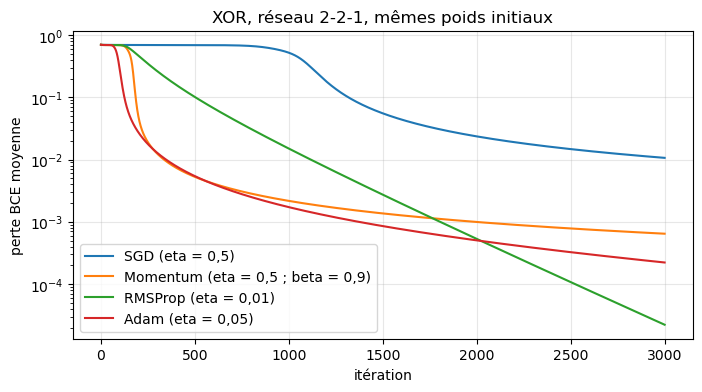

In [11]:
X_xor = torch.tensor([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=torch.float64)
y_xor = torch.tensor([0, 1, 1, 0], dtype=torch.float64)

def reseau_fil_rouge():
    m = nn.Sequential(nn.Linear(2, 2), nn.Sigmoid(), nn.Linear(2, 1), nn.Sigmoid()).double()
    with torch.no_grad():
        m[0].weight.copy_(torch.tensor(W1)); m[0].bias.zero_()
        m[2].weight.copy_(torch.tensor(W2[None, :])); m[2].bias.zero_()
    return m

optimiseurs = {
    "SGD (eta = 0,5)": lambda p: torch.optim.SGD(p, lr=0.5),
    "Momentum (eta = 0,5 ; beta = 0,9)": lambda p: torch.optim.SGD(p, lr=0.5, momentum=0.9),
    "RMSProp (eta = 0,01)": lambda p: torch.optim.RMSprop(p, lr=0.01),
    "Adam (eta = 0,05)": lambda p: torch.optim.Adam(p, lr=0.05),
}
courbes = {}
for nom, fabrique in optimiseurs.items():
    m = reseau_fil_rouge(); opt = fabrique(m.parameters()); hist = []
    for it in range(3000):
        opt.zero_grad()
        l = nn.functional.binary_cross_entropy(m(X_xor).squeeze(1), y_xor)
        l.backward(); opt.step(); hist.append(l.item())
    courbes[nom] = hist
    seuil = next((i + 1 for i, v in enumerate(hist) if v < 0.1), None)
    print(f"{nom:34s} perte < 0,1 après {seuil} itérations ; sorties finales = {m(X_xor).squeeze(1).detach().numpy().round(3)}")

for nom, hist in courbes.items():
    plt.plot(hist, label=nom)
plt.yscale("log"); plt.xlabel("itération"); plt.ylabel("perte BCE moyenne")
plt.title("XOR, réseau 2-2-1, mêmes poids initiaux"); plt.legend(); plt.show()

**À observer.**

- SGD reste longtemps sur un **plateau** autour de $\ln 2 \approx 0{,}693$, la perte d'un réseau qui répond 0,5 partout.
- Le momentum accumule les petits gradients du plateau et en sort beaucoup plus tôt.
- Adam normalise chaque composante du gradient, ce qui accélère aussi.
- Le classement dépend des taux d'apprentissage choisis : comparez toujours des optimiseurs bien réglés.

## 6. Régularisation et métriques sur de petits exemples

### 6.1 Pénalité L2, dropout, batch normalization

In [12]:
# L2 : penalite = lambda/2 ||w||^2, gradient = lambda w ; c'est ce qu'ajoute weight_decay dans torch.optim.SGD
w_ex = np.array([1.0, -2.0]); lam = 0.01
print(f"pénalité L2 = {lam / 2 * np.sum(w_ex ** 2):.3g}   gradient ajouté = {lam * w_ex}   facteur (1 - eta lambda) pour eta = 0,1 : {1 - 0.1 * lam}")
p = torch.tensor(w_ex, requires_grad=True); p.grad = torch.zeros(2, dtype=torch.float64)
torch.optim.SGD([p], lr=0.1, weight_decay=lam).step()
print(f"torch.optim.SGD(weight_decay=0,01), gradient nul : w devient {p.detach().numpy()} = 0,999 x w")

# Dropout inversé, p = 0,5 : en entraînement, les neurones gardés sont multipliés par 1/(1-p) = 2
h_ex = np.array([0.8, 0.2, 0.6, 0.4]); masque = np.array([1, 0, 1, 0])
print(f"\ndropout, masque {masque} : h_tilde = {masque * h_ex / 0.5}")
masques = np.array([[int(c) for c in f"{k:04b}"] for k in range(16)])
print(f"moyenne sur les 16 masques possibles : {(masques * h_ex / 0.5).mean(axis=0)}  = h, l'espérance est conservée")
torch.manual_seed(0)
do = nn.Dropout(p=0.5)
print("nn.Dropout en mode train :", do(torch.ones(8)).numpy(), "| en mode eval :", do.eval()(torch.ones(8)).numpy())

# Batch normalization sur un mini-lot (2, 4, 6)
xb = torch.tensor([[2.0], [4.0], [6.0]])
bn = nn.BatchNorm1d(1)
print(f"\nBatchNorm : moyenne = {xb.mean().item():.3g}, variance = {xb.var(unbiased=False).item():.3g}, x_hat = {bn(xb).detach().squeeze().numpy().round(3)}")

pénalité L2 = 0.025   gradient ajouté = [ 0.01 -0.02]   facteur (1 - eta lambda) pour eta = 0,1 : 0.999
torch.optim.SGD(weight_decay=0,01), gradient nul : w devient [ 0.999 -1.998] = 0,999 x w

dropout, masque [1 0 1 0] : h_tilde = [1.6 0.  1.2 0. ]
moyenne sur les 16 masques possibles : [0.8 0.2 0.6 0.4]  = h, l'espérance est conservée
nn.Dropout en mode train : [0. 0. 2. 0. 0. 0. 2. 2.] | en mode eval : [1. 1. 1. 1. 1. 1. 1. 1.]

BatchNorm : moyenne = 4, variance = 2.67, x_hat = [-1.225  0.     1.225]


### 6.2 Matrice de confusion et piège de l'accuracy

Exemple des diapositives : 1 000 cycles, dont 30 pannes. Le modèle détecte 24 pannes, en rate 6 et lance 12 fausses alertes.

In [13]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

y_vrai = np.array([1] * 30 + [0] * 970)
y_modele = np.array([1] * 24 + [0] * 6 + [1] * 12 + [0] * 958)
y_naif = np.zeros(1000, dtype=int)

print("Matrice de confusion [[TN, FP], [FN, TP]] :\n", confusion_matrix(y_vrai, y_modele))
for nom, yp_ in [("modèle", y_modele), ("naïf « jamais de panne »", y_naif)]:
    print(f"{nom:26s} accuracy = {accuracy_score(y_vrai, yp_):.3f}   précision = {precision_score(y_vrai, yp_, zero_division=0):.3f}   "
          f"rappel = {recall_score(y_vrai, yp_):.3f}   F1 = {f1_score(y_vrai, yp_):.3f}")

Matrice de confusion [[TN, FP], [FN, TP]] :
 [[958  12]
 [  6  24]]
modèle                     accuracy = 0.982   précision = 0.667   rappel = 0.800   F1 = 0.727
naïf « jamais de panne »   accuracy = 0.970   précision = 0.000   rappel = 0.000   F1 = 0.000


### 6.3 MAE et RMSE sur un petit exemple de RUL

On compare des durées de vie restantes (RUL, *Remaining Useful Life*), en cycles :

| | Moteur 1 | Moteur 2 | Moteur 3 | Moteur 4 |
|---|---|---|---|---|
| RUL vraie | 100 | 60 | 30 | 10 |
| RUL prédite | 90 | 70 | 30 | 40 |

In [14]:
rul_vraie = np.array([100, 60, 30, 10.0]); rul_pred = np.array([90, 70, 30, 40.0])
err = rul_pred - rul_vraie
print(f"erreurs = {err}   MAE = {np.abs(err).mean():.3g}   RMSE = {math.sqrt((err ** 2).mean()):.3g}")
print("La RMSE pénalise davantage la grosse erreur de +30. Elle est aussi dangereuse : on annonce 40 cycles alors qu'il n'en reste que 10.")

erreurs = [-10.  10.   0.  30.]   MAE = 12.5   RMSE = 16.6
La RMSE pénalise davantage la grosse erreur de +30. Elle est aussi dangereuse : on annonce 40 cycles alors qu'il n'en reste que 10.


## 7. Cas 1 : classer les pannes (AI4I 2020)

On reprend le jeu du lab 1, avec les **mêmes variables** et le **même découpage** :

- 5 mesures : `T_air`, `T_process`, `vitesse`, `couple` et `usure` ;
- 2 variables métier : la puissance $P = C\,\omega$ et l'écart de température $\Delta T$ ;
- le type de produit (L, M, H), encodé en *one-hot* ;
- un split stratifié 75/25 avec `random_state=42`.

La forêt aléatoire du lab 1 y obtient un **F1 de 0,831**.

### 7.1 Données et forêt aléatoire de référence

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import joblib

URL_AI4I = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
try:
    df = pd.read_csv(URL_AI4I, compression="zip")
except Exception as e:  # repli si le site UCI est indisponible
    print("Téléchargement direct impossible :", e)
    try:
        from ucimlrepo import fetch_ucirepo
    except ImportError:
        %pip install -q ucimlrepo
        from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=601)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)

df.columns = [c.replace("﻿", "").strip() for c in df.columns]
df = df.rename(columns={
    "Air temperature [K]": "T_air_K", "Process temperature [K]": "T_process_K",
    "Rotational speed [rpm]": "vitesse_rpm", "Torque [Nm]": "couple_Nm",
    "Tool wear [min]": "usure_outil_min", "Machine failure": "panne"})
df["puissance_W"] = df["couple_Nm"] * df["vitesse_rpm"] * 2 * np.pi / 60
df["delta_T_K"] = df["T_process_K"] - df["T_air_K"]
VARIABLES = ["T_air_K", "T_process_K", "vitesse_rpm", "couple_Nm", "usure_outil_min", "puissance_W", "delta_T_K"]

X = pd.get_dummies(df[VARIABLES + ["Type"]], columns=["Type"], dtype=float)
y = df["panne"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"{len(df)} cycles, {y.sum()} pannes ({y.mean():.2%}) ; train = {len(X_train)} ({y_train.sum()} pannes), test = {len(X_test)} ({y_test.sum()} pannes)")
print("Entrées :", list(X.columns))

rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced",
                            random_state=SEED, n_jobs=-1).fit(X_train, y_train)
y_rf = rf.predict(X_test)
chemin_rf = os.path.join(DOSSIER, "rf.joblib"); joblib.dump(rf, chemin_rf)
taille_rf = os.path.getsize(chemin_rf)
print(f"Forêt aléatoire (lab 1) : F1 = {f1_score(y_test, y_rf):.3f}   rappel = {recall_score(y_test, y_rf):.3f}   "
      f"précision = {precision_score(y_test, y_rf):.3f}   taille = {taille_rf / 1e6:.1f} Mo")

10000 cycles, 339 pannes (3.39%) ; train = 7500 (254 pannes), test = 2500 (85 pannes)
Entrées : ['T_air_K', 'T_process_K', 'vitesse_rpm', 'couple_Nm', 'usure_outil_min', 'puissance_W', 'delta_T_K', 'Type_H', 'Type_L', 'Type_M']


Forêt aléatoire (lab 1) : F1 = 0.831   rappel = 0.753   précision = 0.928   taille = 3.9 Mo


### 7.2 Préparer les données pour un MLP

Trois différences avec la forêt aléatoire :

1. **Normaliser** les entrées : le couple vaut quelques dizaines de N·m, la vitesse plus de 1 000 tr/min. On centre et on réduit, avec des statistiques calculées sur l'entraînement seul.
2. **Mettre de côté une validation** dans l'entraînement (20 %, stratifiée). Elle sert à l'**arrêt précoce** : on garde l'époque au meilleur F1 de validation. Elle sert aussi au choix du seuil. Le test n'est utilisé qu'à la fin.
3. **Pondérer la perte** : `BCEWithLogitsLoss(pos_weight = n_négatifs / n_positifs)` donne à chaque panne le poids d'environ 29 cycles normaux.

In [16]:
X_app, X_val, y_app, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
normaliseur = StandardScaler().fit(X_app)
vers_tenseur = lambda A: torch.tensor(normaliseur.transform(A), dtype=torch.float32)
Xa_t, Xv_t, Xt_t = vers_tenseur(X_app), vers_tenseur(X_val), vers_tenseur(X_test)
ya_t, yv_t = torch.tensor(y_app, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32)
poids_pos = (y_app == 0).sum() / (y_app == 1).sum()
print(f"apprentissage = {len(X_app)} ({y_app.sum()} pannes), validation = {len(X_val)} ({y_val.sum()} pannes)")
print(f"pos_weight = {poids_pos:.1f}   ;   mini-lots de 64 : {math.ceil(len(X_app) / 64)} mises à jour par époque")

apprentissage = 6000 (203 pannes), validation = 1500 (51 pannes)
pos_weight = 28.6   ;   mini-lots de 64 : 94 mises à jour par époque


In [17]:
def mlp(n_entrees, cachees=(64, 32)):
    couches, d = [], n_entrees
    for h_ in cachees:
        couches += [nn.Linear(d, h_), nn.ReLU()]
        d = h_
    couches.append(nn.Linear(d, 1))
    return nn.Sequential(*couches)

def entrainer(modele, X_a, y_a, X_v, y_v, perte, epoques=150, lr=3e-3, taille_lot=64, patience=30, critere=None):
    # Adam + schedule cosinus + arrêt précoce : on garde les poids de la meilleure époque sur la validation.
    # critere(modele) renvoie un score à maximiser ; par défaut, l'opposé de la perte de validation.
    opt = torch.optim.Adam(modele.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epoques)
    gen = torch.Generator().manual_seed(SEED)
    hist = {"train": [], "val": [], "score": []}
    meilleur, etat, attente = -float("inf"), None, 0
    for ep in range(epoques):
        modele.train(); ordre = torch.randperm(len(X_a), generator=gen); cumul = 0.0
        for i in range(0, len(X_a), taille_lot):
            idx = ordre[i:i + taille_lot]
            opt.zero_grad()
            l = perte(modele(X_a[idx]).squeeze(1), y_a[idx])
            l.backward(); opt.step()
            cumul += l.item() * len(idx)
        sched.step(); modele.eval()
        with torch.no_grad():
            lv = perte(modele(X_v).squeeze(1), y_v).item()
        score = -lv if critere is None else critere(modele)
        hist["train"].append(cumul / len(X_a)); hist["val"].append(lv); hist["score"].append(score)
        if score > meilleur:
            meilleur, etat, attente, ep_best = score, copy.deepcopy(modele.state_dict()), 0, ep
        else:
            attente += 1
            if attente >= patience:
                break
    modele.load_state_dict(etat); modele.eval()
    hist["meilleure_epoque"] = ep_best
    return modele, hist

def proba(modele, X_):
    with torch.no_grad():
        return torch.sigmoid(modele(X_).squeeze(1)).numpy()

SEUILS = np.round(np.arange(0.05, 0.96, 0.05), 2)
def f1_validation(modele):
    # meilleur F1 de validation sur la grille de seuils : c'est la métrique visée, on s'arrête sur elle
    p_ = proba(modele, Xv_t)
    return max(f1_score(y_val, p_ > s_) for s_ in SEUILS)

resultats, modeles = {}, {}
for nom, pw in [("MLP, perte non pondérée", 1.0), ("MLP, perte pondérée", poids_pos)]:
    torch.manual_seed(SEED)
    perte = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pw, dtype=torch.float32))
    t = time.time()
    modele, hist = entrainer(mlp(Xa_t.shape[1]), Xa_t, ya_t, Xv_t, yv_t, perte, critere=f1_validation)
    p_test = proba(modele, Xt_t)
    modeles[nom] = (modele, hist)
    resultats[nom] = dict(F1=f1_score(y_test, p_test > 0.5), rappel=recall_score(y_test, p_test > 0.5),
                          precision=precision_score(y_test, p_test > 0.5), seuil=0.5)
    print(f"{nom:24s} : époque retenue {hist['meilleure_epoque']:3d} (F1 de validation = {max(hist['score']):.3f}), {time.time() - t:.1f} s")

MLP, perte non pondérée  : époque retenue  81 (F1 de validation = 0.833), 5.3 s


MLP, perte pondérée      : époque retenue  33 (F1 de validation = 0.765), 3.0 s


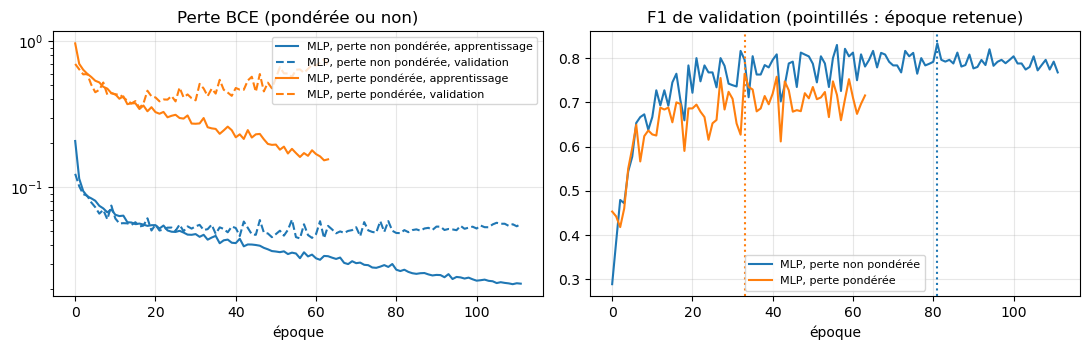

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for nom, (_, hist) in modeles.items():
    l_ = axes[0].plot(hist["train"], label=f"{nom}, apprentissage")
    axes[0].plot(hist["val"], ls="--", color=l_[0].get_color(), label=f"{nom}, validation")
    axes[1].plot(hist["score"], color=l_[0].get_color(), label=nom)
    axes[1].axvline(hist["meilleure_epoque"], color=l_[0].get_color(), ls=":")
axes[0].set_yscale("log"); axes[0].set_title("Perte BCE (pondérée ou non)"); axes[0].set_xlabel("époque"); axes[0].legend(fontsize=8)
axes[1].set_title("F1 de validation (pointillés : époque retenue)"); axes[1].set_xlabel("époque"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7.3 Choisir le seuil de décision sur la validation

La pondération pousse le modèle à signaler plus de pannes : le **rappel monte**, la **précision baisse**. Le seuil de décision est un second réglage.

On le choisit sur la **validation**, pour maximiser le F1, puis on l'applique **tel quel** au test.

In [19]:
modele_pond = modeles["MLP, perte pondérée"][0]
p_val = proba(modele_pond, Xv_t)
f1_val = [f1_score(y_val, p_val > s_) for s_ in SEUILS]
seuil_opt = float(SEUILS[int(np.argmax(f1_val))])
p_test = proba(modele_pond, Xt_t)
resultats["MLP pondéré, seuil choisi sur la validation"] = dict(
    F1=f1_score(y_test, p_test > seuil_opt), rappel=recall_score(y_test, p_test > seuil_opt),
    precision=precision_score(y_test, p_test > seuil_opt), seuil=seuil_opt)
resultats["Forêt aléatoire (lab 1)"] = dict(F1=f1_score(y_test, y_rf), rappel=recall_score(y_test, y_rf),
                                            precision=precision_score(y_test, y_rf), seuil=np.nan)
tableau_ai4i = pd.DataFrame(resultats).T.round(3)
print(f"Seuil retenu sur la validation : {seuil_opt}")
tableau_ai4i

Seuil retenu sur la validation : 0.95


,F1,rappel,precision,seuil
"MLP, perte non pondérée",0.675,0.624,0.736,0.50
"MLP, perte pondérée",0.460,0.835,0.317,0.50
"MLP pondéré, seuil choisi sur la validation",0.671,0.635,0.711,0.95
Forêt aléatoire (lab 1),0.831,0.753,0.928,NaN


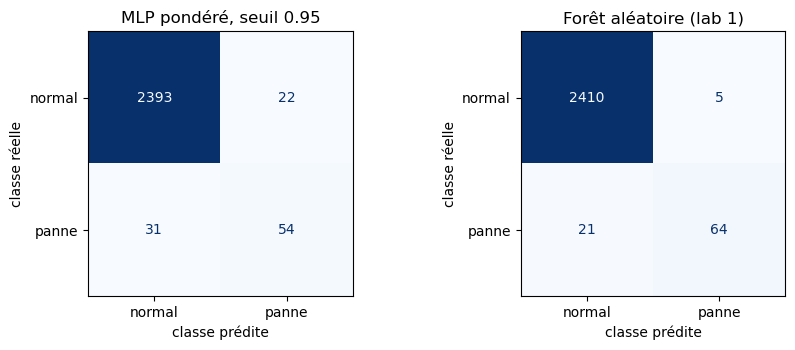

MLP : 2817 paramètres, soit 11268 octets en float32   |   forêt aléatoire : 3.9 Mo sur disque


In [20]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay.from_predictions(y_test, (p_test > seuil_opt).astype(int), display_labels=["normal", "panne"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"MLP pondéré, seuil {seuil_opt}")
ConfusionMatrixDisplay.from_predictions(y_test, y_rf, display_labels=["normal", "panne"], cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title("Forêt aléatoire (lab 1)")
for ax in axes:
    ax.grid(False); ax.set_xlabel("classe prédite"); ax.set_ylabel("classe réelle")
plt.tight_layout(); plt.show()
n_mlp = sum(p.numel() for p in modele_pond.parameters())
print(f"MLP : {n_mlp} paramètres, soit {4 * n_mlp} octets en float32   |   forêt aléatoire : {taille_rf / 1e6:.1f} Mo sur disque")

**À retenir.**

- Sur ce jeu tabulaire de 7 500 lignes d'entraînement, la **forêt aléatoire reste meilleure** que le MLP. C'est un résultat fréquent : sur des données tabulaires de taille moyenne, les arbres battent souvent les réseaux de neurones (Grinsztajn et al., 2022).
- En revanche, le MLP est **plusieurs centaines de fois plus léger**. Sur un microcontrôleur, c'est souvent l'argument décisif.
- La **pondération de la perte** et le **seuil** règlent le compromis entre rappel et précision. En maintenance, rater une panne (FN) coûte en général plus cher qu'une fausse alerte (FP).
- Les valeurs exactes varient de quelques centièmes selon la graine aléatoire et la machine.

## 8. Cas 2 : estimer la durée de vie restante (NASA C-MAPSS FD001)

**Données.** C-MAPSS simule des turboréacteurs qui se dégradent jusqu'à la panne (Saxena et Goebel, 2008). Le sous-ensemble FD001 compte :

- 100 moteurs d'entraînement, suivis jusqu'à la panne ;
- 100 moteurs de test, dont la série s'arrête avant la panne ;
- une seule condition de vol et un seul mode de panne.

Chaque ligne contient le numéro du moteur, le cycle, 3 réglages opérationnels et 21 capteurs. Le fichier `RUL_FD001.txt` donne la RUL vraie à la fin de chaque série de test.

**Source.** On télécharge d'abord l'archive officielle du *NASA Prognostics Data Repository*. En repli, on utilise un miroir GitHub dont les fichiers FD001 sont identiques au MD5 près, vérifié le 23/11/2026.

**Choix classiques** (voir par exemple Heimes, 2008, et Li et al., 2018) :

- la RUL d'entraînement est **plafonnée à 125 cycles**, car un moteur neuf ne montre pas encore de dégradation mesurable ;
- on garde **14 capteurs** : les autres sont constants sur FD001 ;
- la validation se fait **par moteur** (20 moteurs mis de côté), sans mélanger les cycles d'un même moteur. Sinon, des cycles voisins presque identiques se retrouveraient des deux côtés : c'est une **fuite de données**.

In [21]:
URL_NASA = "https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip"
URL_MIROIR = "https://raw.githubusercontent.com/hankroark/Turbofan-Engine-Degradation/master/CMAPSSData/"
COLONNES = ["moteur", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
FICHIERS = ["train_FD001.txt", "test_FD001.txt", "RUL_FD001.txt"]

def lire(contenu, noms):
    return pd.read_csv(io.BytesIO(contenu), sep=r"\s+", header=None, names=noms)

def charger_cmapss():
    try:  # 1) archive officielle NASA (12 Mo, contient CMAPSSData.zip)
        with urllib.request.urlopen(URL_NASA, timeout=60) as r:
            externe = zipfile.ZipFile(io.BytesIO(r.read()))
        interne_nom = [n for n in externe.namelist() if n.endswith("CMAPSSData.zip")][0]
        interne = zipfile.ZipFile(io.BytesIO(externe.read(interne_nom)))
        bruts = {f: interne.read(f) for f in FICHIERS}
        source = "NASA Prognostics Data Repository"
    except Exception as e:  # 2) repli : miroir GitHub (mêmes fichiers)
        print("Archive NASA indisponible :", e, "-> repli sur le miroir GitHub")
        bruts = {}
        for f in FICHIERS:
            with urllib.request.urlopen(URL_MIROIR + f, timeout=60) as r:
                bruts[f] = r.read()
        source = "miroir GitHub hankroark/Turbofan-Engine-Degradation"
    train = lire(bruts["train_FD001.txt"], COLONNES)
    test = lire(bruts["test_FD001.txt"], COLONNES)
    rul = lire(bruts["RUL_FD001.txt"], ["RUL"])
    return train, test, rul, source

cm_train, cm_test, cm_rul, source = charger_cmapss()
print(f"Source : {source}")
print(f"train : {cm_train.shape}, {cm_train.moteur.nunique()} moteurs ; test : {cm_test.shape}, {cm_test.moteur.nunique()} moteurs")
duree = cm_train.groupby("moteur").cycle.max()
print(f"durée de vie en entraînement : de {duree.min()} à {duree.max()} cycles ; plus courte série de test : {cm_test.groupby('moteur').cycle.max().min()} cycles")

Source : NASA Prognostics Data Repository
train : (20631, 26), 100 moteurs ; test : (13096, 26), 100 moteurs
durée de vie en entraînement : de 128 à 362 cycles ; plus courte série de test : 31 cycles


Capteurs écartés, constants ou quasi constants sur FD001 : {'s1': np.float64(0.0), 's5': np.float64(0.0), 's6': np.float64(0.0014), 's10': np.float64(0.0), 's16': np.float64(0.0), 's18': np.float64(0.0), 's19': np.float64(0.0)}
Réglages op1 à op3 écartés : FD001 n'a qu'une condition de vol.


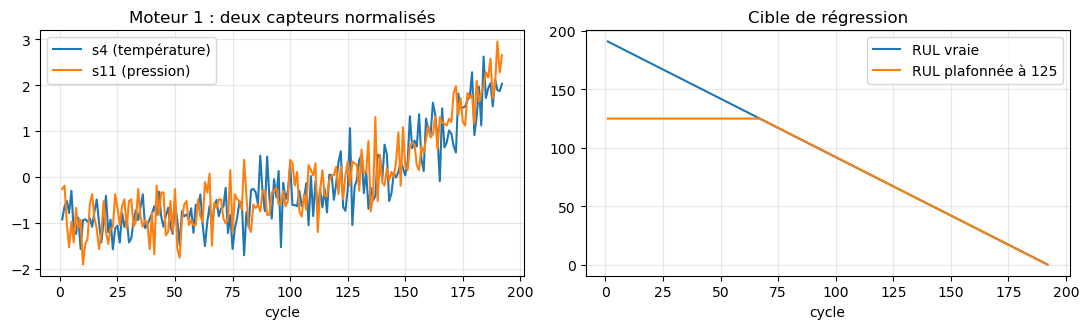

In [22]:
PLAFOND = 125
CAPTEURS_CM = ["s2", "s3", "s4", "s7", "s8", "s9", "s11", "s12", "s13", "s14", "s15", "s17", "s20", "s21"]
ecartes = [c for c in COLONNES[5:] if c not in CAPTEURS_CM]
print("Capteurs écartés, constants ou quasi constants sur FD001 :", {c: round(cm_train[c].std(), 4) for c in ecartes})
print("Réglages op1 à op3 écartés : FD001 n'a qu'une condition de vol.")

cm_train["RUL"] = (cm_train.groupby("moteur").cycle.transform("max") - cm_train.cycle).clip(upper=PLAFOND)

rng = np.random.default_rng(SEED)
moteurs = np.arange(1, 101); rng.shuffle(moteurs)
moteurs_val = set(moteurs[:20].tolist())
app_cm = cm_train[~cm_train.moteur.isin(moteurs_val)]
val_cm = cm_train[cm_train.moteur.isin(moteurs_val)]
mu_cm, sd_cm = app_cm[CAPTEURS_CM].mean().values, app_cm[CAPTEURS_CM].std().values

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
m1 = cm_train[cm_train.moteur == 1]
for c_, lib in [("s4", "s4 (température)"), ("s11", "s11 (pression)")]:
    k = CAPTEURS_CM.index(c_)
    axes[0].plot(m1.cycle, (m1[c_] - mu_cm[k]) / sd_cm[k], label=lib)
axes[0].set_title("Moteur 1 : deux capteurs normalisés"); axes[0].set_xlabel("cycle"); axes[0].legend()
axes[1].plot(m1.cycle, m1.cycle.max() - m1.cycle, label="RUL vraie")
axes[1].plot(m1.cycle, m1.RUL, label=f"RUL plafonnée à {PLAFOND}")
axes[1].set_title("Cible de régression"); axes[1].set_xlabel("cycle"); axes[1].legend()
plt.tight_layout(); plt.show()

### 8.1 Deux MLP : un cycle, ou une fenêtre de 30 cycles

On compare deux entrées pour le même MLP 64-32-1 :

- **(a) le cycle courant seul** : 14 entrées ;
- **(b) une fenêtre glissante des 30 derniers cycles**, aplatie : 14 × 30 = 420 entrées.

La plus courte série de test fait 31 cycles, donc chaque moteur de test a au moins une fenêtre complète. On prédit la RUL à la fin de chaque série de test.

Réglages communs :

- perte MSE ;
- Adam et schedule cosinus ;
- arrêt précoce sur la perte de validation.

In [23]:
def fenetres(d, W, derniere_seulement=False):
    X_, Y_ = [], []
    for _, g_ in d.groupby("moteur"):
        A = ((g_[CAPTEURS_CM].values - mu_cm) / sd_cm).astype(np.float32)
        if derniere_seulement:
            X_.append(A[-W:].ravel())
        else:
            r_ = g_["RUL"].values
            for t in range(W, len(A) + 1):
                X_.append(A[t - W:t].ravel()); Y_.append(r_[t - 1])
    return torch.tensor(np.array(X_)), (torch.tensor(np.array(Y_), dtype=torch.float32) if Y_ else None)

rul_test = np.minimum(cm_rul.RUL.values, PLAFOND)
res_cm, modeles_cm = {}, {}
for nom, W in [("(a) cycle courant", 1), ("(b) fenêtre de 30 cycles", 30)]:
    Xa_c, ya_c = fenetres(app_cm, W); Xv_c, yv_c = fenetres(val_cm, W); Xt_c, _ = fenetres(cm_test, W, derniere_seulement=True)
    torch.manual_seed(SEED); t = time.time()
    modele_c, hist_c = entrainer(mlp(Xa_c.shape[1]), Xa_c, ya_c, Xv_c, yv_c, nn.MSELoss(),
                                 epoques=80, lr=1e-3, taille_lot=256, patience=15)
    with torch.no_grad():
        pred = modele_c(Xt_c).squeeze(1).numpy()
    modeles_cm[nom] = (modele_c, W, Xa_c, Xt_c, pred)
    res_cm[nom] = dict(entrees=Xa_c.shape[1], parametres=sum(p.numel() for p in modele_c.parameters()),
                       RMSE_val=math.sqrt(hist_c["val"][hist_c["meilleure_epoque"]]),
                       RMSE_test=math.sqrt(((pred - rul_test) ** 2).mean()), MAE_test=np.abs(pred - rul_test).mean())
    print(f"{nom:26s} : {len(Xa_c)} exemples d'entraînement, meilleure époque {hist_c['meilleure_epoque']}, {time.time() - t:.1f} s")

rmse_constante = math.sqrt(((app_cm.RUL.mean() - rul_test) ** 2).mean())
print(f"Référence naïve (RUL moyenne constante) : RMSE test = {rmse_constante:.1f} cycles, "
      f"soit {rmse_constante / res_cm['(b) fenêtre de 30 cycles']['RMSE_test']:.1f} fois la RMSE de la fenêtre de 30 cycles")
tableau_cm = pd.DataFrame(res_cm).T
tableau_cm[["RMSE_val", "RMSE_test", "MAE_test"]] = tableau_cm[["RMSE_val", "RMSE_test", "MAE_test"]].astype(float).round(1)
tableau_cm

(a) cycle courant          : 16779 exemples d'entraînement, meilleure époque 70, 2.0 s


(b) fenêtre de 30 cycles   : 14459 exemples d'entraînement, meilleure époque 46, 2.0 s
Référence naïve (RUL moyenne constante) : RMSE test = 42.1 cycles, soit 3.0 fois la RMSE de la fenêtre de 30 cycles


,entrees,parametres,RMSE_val,RMSE_test,MAE_test
(a) cycle courant,14.0,3073.0,18.0,17.3,12.1
(b) fenêtre de 30 cycles,420.0,29057.0,13.4,14.0,10.8


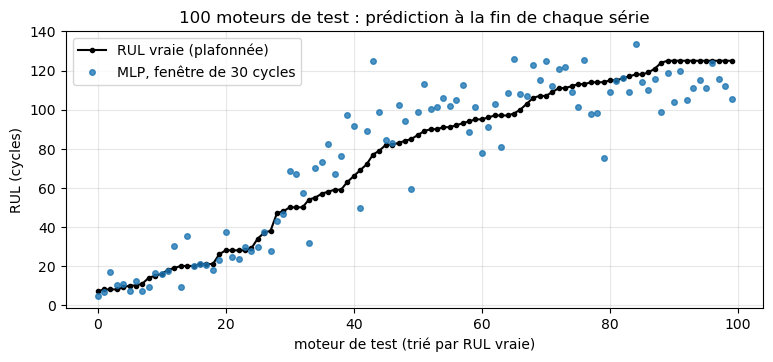

In [24]:
pred_b = modeles_cm["(b) fenêtre de 30 cycles"][4]
ordre = np.argsort(rul_test)
plt.figure(figsize=(9, 3.6))
plt.plot(rul_test[ordre], "k.-", label="RUL vraie (plafonnée)")
plt.plot(pred_b[ordre], "o", ms=4, alpha=0.8, label="MLP, fenêtre de 30 cycles")
plt.xlabel("moteur de test (trié par RUL vraie)"); plt.ylabel("RUL (cycles)")
plt.title("100 moteurs de test : prédiction à la fin de chaque série"); plt.legend(); plt.show()

**À observer.**

- Le contexte temporel aide : la fenêtre de 30 cycles réduit nettement la RMSE. Un MLP traite pourtant la fenêtre comme un vecteur plat, sans notion d'ordre.
- Les **réseaux récurrents** (RNN, LSTM, GRU) de la séance 4 exploitent cet ordre directement.
- Comparez la RMSE à la référence naïve, qui prédit toujours la RUL moyenne : le modèle divise l'erreur par environ trois.

## 9. Vers la cible : mémoire, ONNX, quantification int8

### 9.1 Compter les paramètres

Pour une couche dense $n_\text{in} \to n_\text{out}$, on compte $n_\text{in}\,n_\text{out}$ poids et $n_\text{out}$ biais.

In [25]:
def compter(couches):
    return sum(a * b + b for a, b in zip(couches[:-1], couches[1:]))

FLASH, SRAM = 512 * 1024, 128 * 1024   # STM32F446
for nom, c in [("MLP des diapositives 7 -> 64 -> 32 -> 1", [7, 64, 32, 1]),
               ("MLP AI4I du lab (10 entrées, type one-hot)", [10, 64, 32, 1]),
               ("MLP C-MAPSS fenêtre 30 (420 entrées)", [420, 64, 32, 1])]:
    n = compter(c)
    print(f"{nom:45s} : {n:6d} paramètres -> float32 {4 * n / 1000:6.1f} ko ({4 * n / FLASH:5.1%} de la Flash), int8 {n / 1000:5.1f} ko")
print(f"MAC par inférence du 7-64-32-1 : {7 * 64 + 64 * 32 + 32}")
mac = 7 * 64 + 64 * 32 + 32
print(f"Latence estimée à 180 MHz, 2 à 4 cycles par MAC : {mac * 2 / 180:.0f} à {mac * 4 / 180:.0f} µs (ordre de grandeur, à mesurer sur la cible)")

MLP des diapositives 7 -> 64 -> 32 -> 1       :   2625 paramètres -> float32   10.5 ko ( 2.0% de la Flash), int8   2.6 ko
MLP AI4I du lab (10 entrées, type one-hot)    :   2817 paramètres -> float32   11.3 ko ( 2.1% de la Flash), int8   2.8 ko
MLP C-MAPSS fenêtre 30 (420 entrées)          :  29057 paramètres -> float32  116.2 ko (22.2% de la Flash), int8  29.1 ko
MAC par inférence du 7-64-32-1 : 2528
Latence estimée à 180 MHz, 2 à 4 cycles par MAC : 28 à 56 µs (ordre de grandeur, à mesurer sur la cible)


### 9.2 Export ONNX

ONNX (*Open Neural Network Exchange*) est le format d'échange que lisent les outils embarqués : ST Edge AI (ex-STM32Cube.AI), onnxruntime et les convertisseurs vers LiteRT.

On exporte le MLP **avec sa normalisation**, pour que le modèle embarqué prenne directement les mesures brutes des capteurs.

In [26]:
class AvecNormalisation(nn.Module):
    # (x - mu) / sigma, puis le MLP : les constantes de normalisation voyagent avec le modèle
    def __init__(self, reseau, mu, sigma):
        super().__init__()
        self.reseau = reseau
        self.register_buffer("mu", torch.tensor(np.asarray(mu), dtype=torch.float32))
        self.register_buffer("sigma", torch.tensor(np.asarray(sigma), dtype=torch.float32))
    def forward(self, x):
        return self.reseau((x - self.mu) / self.sigma)

def exporter_onnx(modele, n_entrees, chemin):
    modele = modele.eval(); exemple = torch.randn(4, n_entrees)
    try:  # exporteur par défaut depuis PyTorch 2.9 (torch.export + onnxscript)
        with contextlib.redirect_stdout(io.StringIO()):
            torch.onnx.export(modele, (exemple,), chemin, input_names=["x"], output_names=["y"], dynamo=True,
                              external_data=False, dynamic_shapes=({0: torch.export.Dim("lot")},))
        m_ = onnx.load(chemin); del m_.graph.value_info[:]; onnx.save(m_, chemin)   # évite un conflit d'inférence de forme lors de la quantification
    except Exception as e:  # repli : ancien exporteur TorchScript
        print("Exporteur dynamo indisponible :", type(e).__name__, "-> exporteur TorchScript")
        torch.onnx.export(modele, (exemple,), chemin, input_names=["x"], output_names=["y"], dynamo=False,
                          dynamic_axes={"x": {0: "lot"}, "y": {0: "lot"}})
    onnx.checker.check_model(onnx.load(chemin))
    return chemin

# Modèle AI4I : la normalisation reprend le StandardScaler ; ce modèle travaille sur des float32 bruts
ai4i_complet = AvecNormalisation(copy.deepcopy(modele_pond), normaliseur.mean_, normaliseur.scale_)
onnx_ai4i = exporter_onnx(ai4i_complet, Xa_t.shape[1], os.path.join(DOSSIER, "ai4i_fp32.onnx"))

# Modèle C-MAPSS fenêtre 30 : normalisation capteur par capteur, répétée 30 fois
modele_b = modeles_cm["(b) fenêtre de 30 cycles"][0]
cm_complet = AvecNormalisation(copy.deepcopy(modele_b), np.tile(mu_cm, 30), np.tile(sd_cm, 30))
onnx_cm = exporter_onnx(cm_complet, 420, os.path.join(DOSSIER, "cmapss_fp32.onnx"))
print("Nœuds du graphe AI4I :", [n.op_type for n in onnx.load(onnx_ai4i).graph.node])

Nœuds du graphe AI4I : ['Sub', 'Div', 'Gemm', 'Relu', 'Gemm', 'Relu', 'Gemm']


### 9.3 Quantification int8 dynamique (onnxruntime)

`quantize_dynamic` stocke les **poids en int8** et calcule l'échelle des activations **à la volée**, à chaque inférence.

On compare ensuite trois grandeurs avant et après quantification :

- la taille du fichier ;
- la métrique, F1 pour AI4I et RMSE pour C-MAPSS ;
- l'écart entre les sorties des deux modèles.

In [27]:
import onnxruntime as ort
from onnxruntime.quantization import quantize_dynamic, QuantType

def session(chemin):
    return ort.InferenceSession(chemin, providers=["CPUExecutionProvider"])

def predire(chemin, X_):
    s = session(chemin)
    return s.run(None, {"x": np.asarray(X_, dtype=np.float32)})[0].ravel()

int8_ai4i = os.path.join(DOSSIER, "ai4i_int8.onnx"); quantize_dynamic(onnx_ai4i, int8_ai4i, weight_type=QuantType.QInt8)
int8_cm = os.path.join(DOSSIER, "cmapss_int8.onnx"); quantize_dynamic(onnx_cm, int8_cm, weight_type=QuantType.QInt8)

# AI4I : entrées brutes (non normalisées), seuil choisi sur la validation
X_test_brut = X_test.values.astype(np.float32)
lignes = []
for nom, chemin in [("float32", onnx_ai4i), ("int8", int8_ai4i)]:
    p_ = sigmoide(predire(chemin, X_test_brut))
    lignes.append(dict(modele="AI4I", version=nom, taille_octets=os.path.getsize(chemin),
                       metrique="F1", valeur=f1_score(y_test, p_ > seuil_opt)))
p32, p8 = sigmoide(predire(onnx_ai4i, X_test_brut)), sigmoide(predire(int8_ai4i, X_test_brut))
print(f"AI4I : écart max de probabilité float32 / int8 = {np.abs(p32 - p8).max():.4f} ; "
      f"décisions identiques sur {np.mean((p32 > seuil_opt) == (p8 > seuil_opt)):.1%} du test")

# C-MAPSS : fenêtres brutes (non normalisées)
Xt_brut = np.array([g_[CAPTEURS_CM].values[-30:].ravel() for _, g_ in cm_test.groupby("moteur")], dtype=np.float32)
for nom, chemin in [("float32", onnx_cm), ("int8", int8_cm)]:
    r_ = predire(chemin, Xt_brut)
    lignes.append(dict(modele="C-MAPSS", version=nom, taille_octets=os.path.getsize(chemin),
                       metrique="RMSE", valeur=math.sqrt(((r_ - rul_test) ** 2).mean())))
r32, r8 = predire(onnx_cm, Xt_brut), predire(int8_cm, Xt_brut)
print(f"C-MAPSS : écart max de RUL float32 / int8 = {np.abs(r32 - r8).max():.2f} cycles")
tableau_q = pd.DataFrame(lignes)
tableau_q["taille_ko"] = (tableau_q.taille_octets / 1000).round(1)
tableau_q["part_Flash_STM32F446"] = (tableau_q.taille_octets / FLASH * 100).round(1).astype(str) + " %"
tableau_q["valeur"] = tableau_q["valeur"].round(3)
for m_ in ["AI4I", "C-MAPSS"]:
    t_ = tableau_q[tableau_q.modele == m_].taille_octets.values
    print(f"{m_} : fichier float32 / fichier int8 = {t_[0] / t_[1]:.1f}")
tableau_q

AI4I : écart max de probabilité float32 / int8 = 0.0454 ; décisions identiques sur 99.9% du test
C-MAPSS : écart max de RUL float32 / int8 = 2.74 cycles
AI4I : fichier float32 / fichier int8 = 1.9
C-MAPSS : fichier float32 / fichier int8 = 3.2


,modele,version,taille_octets,metrique,valeur,taille_ko,part_Flash_STM32F446
0,AI4I,float32,19915,F1,0.671,19.9,3.8 %
1,AI4I,int8,10513,F1,0.671,10.5,2.0 %
2,C-MAPSS,float32,128165,RMSE,14.041,128.2,24.4 %
3,C-MAPSS,int8,40050,RMSE,13.950,40.0,7.6 %


**À observer.**

- Pour le modèle C-MAPSS (29 057 paramètres), le fichier int8 est environ **3 fois plus petit**, pour une RMSE quasiment inchangée. On n'atteint pas 4 : les biais restent en float32 et le graphe ajoute des nœuds.
- Pour le petit MLP AI4I, le gain est moindre : avec 2 817 paramètres seulement, la description du graphe et les nœuds ajoutés par la quantification (`DynamicQuantizeLinear`, `MatMulInteger`) pèsent autant que les poids.
- Sur cible, l'outil (ST Edge AI, LiteRT pour microcontrôleurs) génère du **C** avec des tableaux constants en Flash : seuls comptent alors les octets des poids et des activations.

### 9.4 La quantification à la main

Exemple des diapositives : des valeurs dans $[-1{,}0 ;\ 1{,}55]$, codées en int8 $[-128 ;\ 127]$.

In [28]:
xmin, xmax = -1.0, 1.55
s = (xmax - xmin) / 255
z = int(-128 - round(xmin / s))
print(f"s = {s:.3g}   z = {z}")
for xq in [-1.0, 0.5, -0.734, 1.55]:
    q = int(np.clip(round(xq / s) + z, -128, 127))
    x_hat = s * (q - z)
    print(f"x = {xq:+.3f} -> q = {q:+4d} -> x_hat = {x_hat:+.3f}   erreur = {abs(xq - x_hat):.3f}  (au plus s/2 = {s / 2:.3f})")

# Les poids réellement quantifiés du MLP C-MAPSS (première couche)
W_c = modele_b[0].weight.detach().numpy()
s_w = np.abs(W_c).max() / 127             # quantification symétrique (z = 0), courante pour les poids
W_q = np.clip(np.round(W_c / s_w), -127, 127)
print(f"\nCouche 1 du MLP C-MAPSS : {W_c.size} poids, |w| max = {np.abs(W_c).max():.3f}, s = {s_w:.2e}, "
      f"erreur max = {np.abs(W_c - s_w * W_q).max():.2e} (s/2 = {s_w / 2:.2e})")

s = 0.01   z = -28
x = -1.000 -> q = -128 -> x_hat = -1.000   erreur = 0.000  (au plus s/2 = 0.005)
x = +0.500 -> q =  +22 -> x_hat = +0.500   erreur = 0.000  (au plus s/2 = 0.005)
x = -0.734 -> q = -101 -> x_hat = -0.730   erreur = 0.004  (au plus s/2 = 0.005)
x = +1.550 -> q = +127 -> x_hat = +1.550   erreur = 0.000  (au plus s/2 = 0.005)

Couche 1 du MLP C-MAPSS : 26880 poids, |w| max = 0.401, s = 3.16e-03, erreur max = 1.58e-03 (s/2 = 1.58e-03)


### 9.5 Pour aller plus loin : quantification statique

Sur microcontrôleur, on veut aussi les **activations en int8**. Leurs échelles sont alors fixées à l'avance, sur un petit jeu de **calibration**. C'est la quantification **statique**, ici au format QDQ (*QuantizeLinear / DequantizeLinear*). Les chaînes embarquées utilisent ce type de modèle.

In [29]:
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantFormat

class Calibration(CalibrationDataReader):
    def __init__(self, X_):
        self.lots = iter([{"x": X_[i:i + 32]} for i in range(0, len(X_), 32)])
    def get_next(self):
        return next(self.lots, None)

# 512 fenêtres d'entraînement brutes, tirées au hasard
Xa_brut = np.array([g_[CAPTEURS_CM].values[t - 30:t].ravel() for _, g_ in app_cm.groupby("moteur")
                    for t in range(30, len(g_) + 1)], dtype=np.float32)
calib = Xa_brut[np.random.default_rng(SEED).choice(len(Xa_brut), 512, replace=False)]
qdq_cm = os.path.join(DOSSIER, "cmapss_int8_statique.onnx")
quantize_static(onnx_cm, qdq_cm, Calibration(calib), quant_format=QuantFormat.QDQ,
                activation_type=QuantType.QInt8, weight_type=QuantType.QInt8)
r_s = predire(qdq_cm, Xt_brut)
print(f"C-MAPSS int8 statique : {os.path.getsize(qdq_cm) / 1000:.1f} ko, RMSE test = {math.sqrt(((r_s - rul_test) ** 2).mean()):.2f} "
      f"(float32 : {math.sqrt(((r32 - rul_test) ** 2).mean()):.2f})")

C-MAPSS int8 statique : 41.9 ko, RMSE test = 14.19 (float32 : 14.04)


## 10. Exercices de validation

Chaque fonction renvoie `None` tant qu'elle n'est pas complétée. Le vérificateur affiche alors « À compléter », puis « Correct » une fois la fonction juste. Remplacez `return None` par votre code, puis relancez la cellule.

In [30]:
def verifier(nom, test):
    # test() renvoie None (non complété), True (juste) ou False (faux) ; une erreur ne bloque pas le notebook
    try:
        r = test()
    except Exception as e:
        print(f"{nom} : erreur à l'exécution ({type(e).__name__} : {e})")
        return
    if r is None:
        print(f"{nom} : À compléter")
    else:
        print(f"{nom} : {'Correct' if r else 'Incorrect, relisez la formule'}")

### Exercice 1 — Gradient d'un neurone

Complétez `grad_neurone(x, w, b, y)`. Elle renvoie le couple $\left(\dfrac{\partial \mathcal{L}}{\partial w}, \dfrac{\partial \mathcal{L}}{\partial b}\right)$ pour $\hat y = \sigma(wx+b)$ et $\mathcal{L} = \tfrac12(\hat y - y)^2$.

In [31]:
def grad_neurone(x, w, b, y):
    # À compléter : renvoyer (dL_dw, dL_db)
    return None

def test_ex1():
    r = grad_neurone(2.0, 0.5, -0.5, 1.0)
    if r is None:
        return None
    ok = np.allclose(r, (-0.177447, -0.088723), atol=1e-4)
    t = torch.tensor([0.7, -1.2], requires_grad=True)          # vérification par autograd sur un autre cas
    (0.5 * (torch.sigmoid(t[0] * 1.5 + t[1]) - 0.0) ** 2).backward()
    return ok and np.allclose(grad_neurone(1.5, 0.7, -1.2, 0.0), t.grad.numpy(), atol=1e-6)

verifier("Exercice 1", test_ex1)

Exercice 1 : À compléter


### Exercice 2 — Le δ d'une couche cachée

Complétez `delta_cache(W2, delta2, z1)`. Elle renvoie $\delta_1 = \big(W_2^\top \delta_2\big)\odot\sigma'(z_1)$, où :

- $W_2$ est une matrice $(n_\text{sortie}, n_\text{caché})$ ;
- $\delta_2$ est un vecteur de taille $n_\text{sortie}$ ;
- $z_1$ est un vecteur de taille $n_\text{caché}$.

In [32]:
def delta_cache(W2, delta2, z1):
    # À compléter : renvoyer le vecteur delta1
    return None

def test_ex2():
    r = delta_cache(np.array([[1.0, -1.0]]), np.array([-0.4879981]), np.array([0.5, 0.3]))
    if r is None:
        return None
    ok = np.allclose(r, [-0.114681, 0.119295], atol=1e-5)
    rng_ = np.random.default_rng(1)
    W2_, d2_, z1_ = rng_.normal(size=(3, 4)), rng_.normal(size=3), rng_.normal(size=4)
    return ok and np.allclose(delta_cache(W2_, d2_, z1_), (W2_.T @ d2_) * sigmoide(z1_) * (1 - sigmoide(z1_)))

verifier("Exercice 2", test_ex2)

Exercice 2 : À compléter


### Exercice 3 — Un pas d'Adam

Complétez `pas_adam(theta, g, m, v, t, lr, beta1, beta2, eps)`. La fonction prend en entrée $\theta$, $m$ et $v$ au pas $t-1$, et le pas courant $t$, qui commence à 1.

Elle renvoie `(theta, m, v)` mis à jour, **avec la correction de biais**. Le vérificateur compare 5 pas à `torch.optim.Adam`.

In [33]:
def pas_adam(theta, g, m, v, t, lr=0.1, beta1=0.9, beta2=0.999, eps=1e-8):
    # À compléter : renvoyer (theta, m, v)
    return None

def test_ex3():
    if pas_adam(np.ones(2), np.ones(2), np.zeros(2), np.zeros(2), 1) is None:
        return None
    rng_ = np.random.default_rng(3)
    grads = rng_.normal(size=(5, 3))
    th, m_, v_ = np.array([1.0, -2.0, 0.5]), np.zeros(3), np.zeros(3)
    p = torch.tensor(th.copy(), requires_grad=True)
    opt_ = torch.optim.Adam([p], lr=0.1, betas=(0.9, 0.999), eps=1e-8)
    for t, g_ in enumerate(grads, start=1):
        th, m_, v_ = pas_adam(th, g_, m_, v_, t)
        p.grad = torch.tensor(g_); opt_.step()
    return np.allclose(th, p.detach().numpy(), atol=1e-6)

verifier("Exercice 3", test_ex3)

Exercice 3 : À compléter


### Exercice 4 — Précision, rappel, F1

Complétez `metriques(tp, fp, fn, tn)`. Elle renvoie le tuple `(precision, rappel, f1, accuracy)`. Le vérificateur utilise l'exemple des diapositives, puis la forêt aléatoire sur AI4I.

In [34]:
def metriques(tp, fp, fn, tn):
    # À compléter : renvoyer (precision, rappel, f1, accuracy)
    return None

def test_ex4():
    r = metriques(24, 12, 6, 958)
    if r is None:
        return None
    ok = np.allclose(r, (2 / 3, 0.8, 0.727273, 0.982), atol=1e-4)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, y_rf).ravel()
    return ok and np.isclose(metriques(tp_, fp_, fn_, tn_)[2], f1_score(y_test, y_rf))

verifier("Exercice 4", test_ex4)

Exercice 4 : À compléter


### Exercice 5 — Quantifier en int8

Complétez `quantifier_int8(x, xmin, xmax)`. Elle renvoie `(q, s, z)` :

- `q` est un tableau d'entiers dans $[-128 ;\ 127]$, écrêté si besoin ;
- `s` vaut $\dfrac{x_\max - x_\min}{255}$ ;
- `z` vaut $-128 - \mathrm{round}(x_\min/s)$.

In [35]:
def quantifier_int8(x, xmin, xmax):
    # À compléter : renvoyer (q, s, z)
    return None

def test_ex5():
    r = quantifier_int8(np.array([-1.0, 0.5, -0.734, 1.55, 3.0]), -1.0, 1.55)
    if r is None:
        return None
    q, s_, z_ = r
    return (np.isclose(s_, 0.01) and int(z_) == -28 and list(np.asarray(q).astype(int)) == [-128, 22, -101, 127, 127])

verifier("Exercice 5", test_ex5)

Exercice 5 : À compléter


## 11. Corrigé

Essayez d'abord les exercices ! Cette section définit les solutions, puis relance les vérificateurs.

In [36]:
def grad_neurone(x, w, b, y):
    z_ = w * x + b
    yh = sigmoide(z_)
    dz = (yh - y) * yh * (1 - yh)      # dL/dy_hat * sigma'(z)
    return dz * x, dz

def delta_cache(W2, delta2, z1):
    s_ = sigmoide(z1)
    return (W2.T @ delta2) * s_ * (1 - s_)

def pas_adam(theta, g, m, v, t, lr=0.1, beta1=0.9, beta2=0.999, eps=1e-8):
    m = beta1 * m + (1 - beta1) * g
    v = beta2 * v + (1 - beta2) * g ** 2
    m_hat = m / (1 - beta1 ** t)
    v_hat = v / (1 - beta2 ** t)
    return theta - lr * m_hat / (np.sqrt(v_hat) + eps), m, v

def metriques(tp, fp, fn, tn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    rappel = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel else 0.0
    return precision, rappel, f1, (tp + tn) / (tp + fp + fn + tn)

def quantifier_int8(x, xmin, xmax):
    s_ = (xmax - xmin) / 255
    z_ = int(-128 - round(xmin / s_))
    q = np.clip(np.round(np.asarray(x) / s_) + z_, -128, 127).astype(np.int8)
    return q, s_, z_

for nom, test in [("Exercice 1", test_ex1), ("Exercice 2", test_ex2), ("Exercice 3", test_ex3),
                  ("Exercice 4", test_ex4), ("Exercice 5", test_ex5)]:
    verifier(nom, test)

Exercice 1 : Correct
Exercice 2 : Correct
Exercice 3 : Correct
Exercice 4 : Correct
Exercice 5 : Correct


## Nettoyage

On supprime les fichiers temporaires : modèles ONNX et forêt aléatoire.

In [37]:
shutil.rmtree(DOSSIER, ignore_errors=True)
print(f"Dossier temporaire supprimé. Durée totale d'exécution : {time.time() - T0:.0f} s")

Dossier temporaire supprimé. Durée totale d'exécution : 43 s


## Références

- Rumelhart, Hinton et Williams (1986), *Learning representations by back-propagating errors*, Nature.
- Glorot et Bengio (2010), *Understanding the difficulty of training deep feedforward neural networks*, AISTATS.
- He, Zhang, Ren et Sun (2015), *Delving Deep into Rectifiers*, ICCV.
- Kingma et Ba (2014), *Adam: A Method for Stochastic Optimization*, arXiv:1412.6980.
- Loshchilov et Hutter (2019), *Decoupled Weight Decay Regularization*, ICLR.
- Srivastava et al. (2014), *Dropout*, JMLR ; Ioffe et Szegedy (2015), *Batch Normalization*, ICML.
- Grinsztajn, Oyallon et Varoquaux (2022), *Why do tree-based models still outperform deep learning on tabular data?*, NeurIPS.
- Matzka (2020), *Explainable Artificial Intelligence for Predictive Maintenance Applications*, AI4I (jeu AI4I 2020, UCI, CC BY 4.0).
- Saxena, Goebel, Simon et Eklund (2008), *Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation*, PHM ; Saxena et Goebel (2008), *Turbofan Engine Degradation Simulation Data Set*, NASA Prognostics Data Repository.
- Heimes (2008), *Recurrent neural networks for remaining useful life estimation*, PHM ; Li, Ding et Sun (2018), *Remaining useful life estimation in prognostics using deep convolution neural networks*, Reliability Engineering & System Safety.